# Soluciones · Datos desbalanceados con fraudes reales

Dataset real: **284.807 transacciones con tarjeta**, de las que solo **492 son fraude**.
Las columnas `V1`–`V28` están anonimizadas por privacidad; `Amount` es el importe.

Completa las celdas marcadas con `# TU CÓDIGO AQUÍ`.

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE

datos = fetch_openml(data_id=1597, as_frame=True)
X = datos.data
y = datos.target.astype(int)
X.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99


## Ejercicio 1 · ¿Cuánto desbalance hay?
1. Calcula cuántas transacciones hay de cada clase y qué **porcentaje** son fraude.
2. Si un modelo dijera siempre "normal", ¿qué accuracy tendría?

In [2]:
print(y.value_counts())
print(y.value_counts(normalize=True))
y_pred_tonto = np.zeros_like(y)
print(accuracy_score(y, y_pred_tonto))

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64
0.9982725143693799


**Respuesta:** fraude = 0,17 %. Un modelo que siempre dice "normal" tendría 99,83 % de accuracy.

## Ejercicio 2 · Modelo baseline
Separa train y test (30 %, **estratificado**) y entrena el modelo baseline.
Luego mira el `classification_report`: ¿qué **recall** tiene la clase 1?

> `StandardScaler` es necesario porque `Amount` tiene una escala muy distinta a las otras columnas.

              precision    recall  f1-score   support

           0      0.999     1.000     1.000     85295
           1      0.858     0.615     0.717       148

    accuracy                          0.999     85443
   macro avg      0.929     0.807     0.858     85443
weighted avg      0.999     0.999     0.999     85443



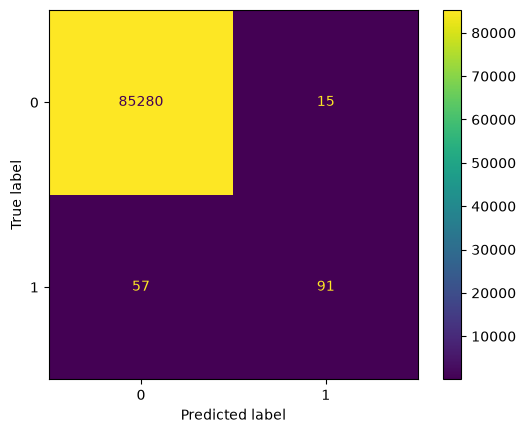

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)
print(classification_report(y_test, y_pred, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred);

## Ejercicio 3 · `class_weight='balanced'`
Entrena el mismo modelo con `class_weight="balanced"`. ¿Qué pasa con el recall? ¿Y con la precision?

              precision    recall  f1-score   support

           0      1.000     0.978     0.989     85295
           1      0.064     0.872     0.119       148

    accuracy                          0.978     85443
   macro avg      0.532     0.925     0.554     85443
weighted avg      0.998     0.978     0.987     85443



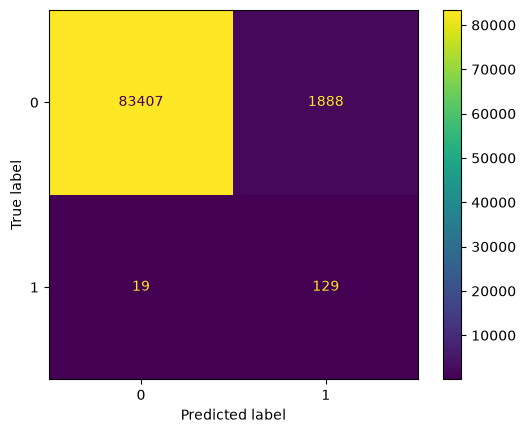

In [4]:
modelo_cw = make_pipeline(StandardScaler(),
                          LogisticRegression(max_iter=1000, class_weight="balanced"))
modelo_cw.fit(X_train, y_train)
y_pred_cw = modelo_cw.predict(X_test)

print(classification_report(y_test, y_pred_cw, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_cw);


**Respuesta:** el recall sube de 0,615 a 0,872, pero la precision baja de 0,858 a 0,064: muchas más falsas alarmas (1.888).

## Ejercicio 4 · SMOTE
Aplica SMOTE **solo al train** y entrena el modelo baseline con los datos nuevos.
¿Cuántos ejemplos tiene ahora el train de cada clase?

> ⚠️ Si aplicas SMOTE antes del split, el resultado será falso (data leakage).

Class
0    199020
1    199020
Name: count, dtype: int64
              precision    recall  f1-score   support

           0      1.000     0.983     0.991     85295
           1      0.080     0.858     0.146       148

    accuracy                          0.983     85443
   macro avg      0.540     0.920     0.568     85443
weighted avg      0.998     0.983     0.990     85443



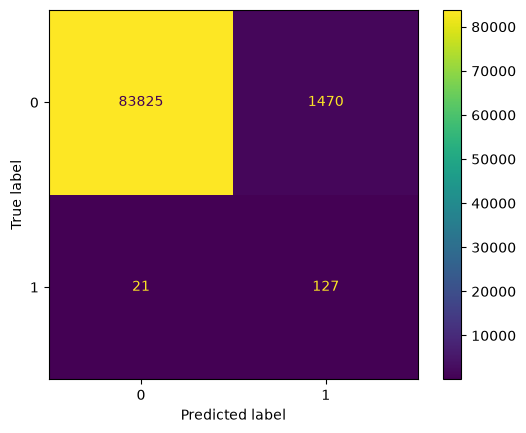

In [5]:
# 1. SMOTE solo en el train
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

# 2. ¿Cuántos ejemplos de cada clase hay ahora?
print(y_train_sm.value_counts())

# 3. Modelo baseline entrenado con los datos nuevos
modelo_sm = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
modelo_sm.fit(X_train_sm, y_train_sm)
y_pred_sm = modelo_sm.predict(X_test)

print(classification_report(y_test, y_pred_sm, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_sm);

**Respuesta:** el train tiene ahora 199.020 ejemplos de cada clase. El resultado es muy parecido a class_weight: recall 0,858, precision 0,080.

## Ejercicio 5 · Mover el umbral
Usa las probabilidades del modelo baseline (`predict_proba`) y prueba los umbrales `0.5, 0.3, 0.1, 0.05, 0.02`.
Para cada uno, calcula precision, recall y F1. ¿Cuál tiene mejor F1?

In [6]:
proba = modelo.predict_proba(X_test)[:, 1]

for t in [0.5, 0.3, 0.1, 0.05, 0.02]:
    y_t = (proba >= t).astype(int)
    print(t,
          "precision:", round(precision_score(y_test, y_t, zero_division=0), 3),
          "recall:", round(recall_score(y_test, y_t), 3),
          "F1:", round(f1_score(y_test, y_t), 3))

0.5 precision: 0.858 recall: 0.615 F1: 0.717
0.3 precision: 0.782 recall: 0.655 F1: 0.713
0.1 precision: 0.746 recall: 0.716 F1: 0.731
0.05 precision: 0.697 recall: 0.777 F1: 0.735
0.02 precision: 0.567 recall: 0.824 F1: 0.672


**Respuesta:** el mejor F1 es con umbral 0,05 (0,735). Bajar el umbral sube el recall sin hundir la precision, como pasaba con class_weight.

## Ejercicio 6 · Eres el banco 🏦
- Cada **falsa alarma** cuesta **5 €** (hay que llamar al cliente).
- Cada **fraude no detectado** cuesta **200 €**.

Usa la función `coste` para calcular cuánto cuesta cada técnica. **¿Cuál elegirías?**

In [7]:
from sklearn.metrics import confusion_matrix

def coste(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fp * 5 + fn * 200

print("Baseline:    ", coste(y_test, y_pred), "€")
print("class_weight:", coste(y_test, y_pred_cw), "€")
print("SMOTE:       ", coste(y_test, y_pred_sm), "€")

for t in [0.5, 0.3, 0.1, 0.05, 0.02]:
    y_t = (proba >= t).astype(int)
    print("Umbral", t, ":", coste(y_test, y_t), "€")

Baseline:     11475 €
class_weight: 13240 €
SMOTE:        11550 €
Umbral 0.5 : 11475 €
Umbral 0.3 : 10335 €
Umbral 0.1 : 8580 €
Umbral 0.05 : 6850 €
Umbral 0.02 : 5665 €


**Respuesta:** la más barata es bajar el umbral a 0,02 (5.665 €). class_weight es la más cara (13.240 €) por sus 1.888 falsas alarmas.

## Para pensar
¿La técnica con mejor **recall** es también la más barata? ¿Por qué?

**Respuesta:** no. La técnica con mejor recall es class_weight (0,872), pero es la más cara (13.240 €): pilla casi todos los fraudes, pero da 1.888 falsas alarmas, y todas esas llamadas suman. La más barata es bajar el umbral a 0,02 (5.665 €), porque encuentra el equilibrio entre pillar fraudes y no molestar a los clientes. No hay técnica mágica: la mejor depende de lo que cueste cada error.